### Import Complete Lord of the Rings Text -- No Book or Chapter Divisons

In [2]:
# complete texts of Lord of the Rings can be located at 
# 'https://archive.org/details/TheLordOfTheRing1TheFellowshipOfTheRing'

In [3]:
with open('./the_lord_of_the_rings_text/Lord_of_the_Rings_complete.txt', 'r') as file:
    lotr = file.read().replace('\n', '')

In [4]:
# check the size of the string to double check
# 2_512_368 characters 
len(lotr)

2512368

In [5]:
# Leaving the corpus as one long string is optimal for NLP

### Prepare Corpus for NLP (Tokenize, Punctuation Removal, Stopwords)

In [6]:
import nltk;
from nltk.corpus import stopwords;
from nltk.stem import WordNetLemmatizer;
from nltk.tokenize import RegexpTokenizer;

In [7]:
# remove punctuation and tokenize

tokenizer = RegexpTokenizer(r'\w+') # Separating by word using Regular Expressions 
lotr_tokens = tokenizer.tokenize(lotr)

# Keeping capitalization because I want the model to treat the proper nouns accordingly. Names are important in LotR. 

In [8]:
lotr_tokens[2019]

'Hobbits'

### Stopwords 

In [9]:
# Knowing how sensitive LDA models can be regarding word counts; I'm reticent to remove any additional stopwords. 

stopwords = nltk.corpus.stopwords.words('english')

In [10]:
# Some of these are lemma so I'll do a second stopword sweep during CountVectorization and Tf-Idf. 
# I'd rather add/subtract stopwords early in the process. 
print(stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [11]:
# Removes stopwords and gives a count of words before and after removal

lotr_clean = [word for word in lotr_tokens if word.lower() not in stopwords]
print("="*90)
print(f'Length of original list: {len(lotr_tokens)} words\n')
print(f'Length of list after stopwords removal: {len(lotr_clean)} words')

Length of original list: 482056 words

Length of list after stopwords removal: 228086 words


In [12]:
lotr_clean[2019]

'workshops'

In [13]:
# Lemmatize tokens

lemmatizer = WordNetLemmatizer()
lotr_tokens_lems = [lemmatizer.lemmatize(i) for i in lotr_clean]

In [14]:
# 'Workshops' has been reduced to its root, or lemma, 'workshop'.

lotr_tokens_lems[2019]

'workshop'

In [15]:
import sklearn;
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

In [16]:
# Graciously borrowed from 'https://www.kaggle.com/meiyizi/spooky-nlp-and-topic-modelling-tutorial' 
# We have essentially inherited and subclassed the original Sklearn's CountVectorizer class 
# and overwritten the build_analyzer method by implementing the lemmatizer for each list in the raw text matrix.

lemm = WordNetLemmatizer() 
class LemmaCountVectorizer(CountVectorizer): # the parent class 
    def build_analyzer(self):
        analyzer = super(LemmaCountVectorizer, self).build_analyzer() # the child class
        # 'super' is short for 'superimpose'
        # super() helps to specifically call the Parent class method 
        # which has been overridden in the child class, from the child class.
        return lambda doc: (lemm.lemmatize(w) for w in analyzer(doc))    

In [17]:
print(ENGLISH_STOP_WORDS)

frozenset({'been', 'de', 'so', 'sincere', 'only', 'across', 'made', 'or', 'but', 'take', 'why', 'top', 'would', 'beside', 'his', 'eight', 'amount', 'though', 'were', 'onto', 'afterwards', 'around', 'into', 'even', 'much', 'serious', 'others', 'hundred', 'perhaps', 'get', 'keep', 'mostly', 'whom', 'somewhere', 'eleven', 'side', 'becoming', 'without', 'moreover', 'almost', 'wherever', 'these', 'am', 'rather', 'in', 'most', 'eg', 'i', 'whole', 'will', 'everything', 'while', 'least', 'many', 'both', 'when', 'throughout', 'here', 'still', 'sometimes', 'could', 'be', 'has', 'own', 'for', 'please', 'ever', 'yours', 'last', 'thereby', 'twenty', 'else', 'itself', 'hence', 'first', 're', 'might', 'etc', 'un', 'wherein', 'fill', 'alone', 'now', 'below', 'this', 'whatever', 'a', 'myself', 'thru', 'amongst', 'go', 'neither', 'cannot', 'sometime', 'ten', 'full', 'interest', 'on', 'latterly', 'how', 'me', 'four', 'thereafter', 'about', 'between', 'may', 'the', 'third', 'cant', 'they', 'those', 'namel

In [18]:
sets = [frozenset(ENGLISH_STOP_WORDS), set(stopwords)] # Combines both stopword lists into a master list 
 
master_stops = ([list(x) for x in sets])

In [19]:
# Our unaltered master list of stop words; including duplicates
print(master_stops)

[['been', 'de', 'so', 'sincere', 'only', 'across', 'made', 'or', 'but', 'take', 'why', 'top', 'would', 'beside', 'his', 'eight', 'amount', 'though', 'were', 'onto', 'afterwards', 'around', 'into', 'even', 'much', 'serious', 'others', 'hundred', 'perhaps', 'get', 'keep', 'mostly', 'whom', 'somewhere', 'eleven', 'side', 'becoming', 'without', 'moreover', 'almost', 'wherever', 'these', 'am', 'rather', 'in', 'most', 'eg', 'i', 'whole', 'will', 'everything', 'while', 'least', 'many', 'both', 'when', 'throughout', 'here', 'still', 'sometimes', 'could', 'be', 'has', 'own', 'for', 'please', 'ever', 'yours', 'last', 'thereby', 'twenty', 'else', 'itself', 'hence', 'first', 're', 'might', 'etc', 'un', 'wherein', 'fill', 'alone', 'now', 'below', 'this', 'whatever', 'a', 'myself', 'thru', 'amongst', 'go', 'neither', 'cannot', 'sometime', 'ten', 'full', 'interest', 'on', 'latterly', 'how', 'me', 'four', 'thereafter', 'about', 'between', 'may', 'the', 'third', 'cant', 'they', 'those', 'namely', 'coul

In [20]:
# Create lambda function to combine or flatten our list of lists

flatten = lambda master_stops: [item for sublist in master_stops for item in sublist]

In [21]:
# Apply lambda function

flat_master_stops = flatten(master_stops)

In [22]:
# Unique stopwords in our master list 

print(set(flat_master_stops))

{'been', 'de', 'so', 'sincere', 'only', 'having', 'across', 'made', 'take', 'or', 'but', 't', 'why', 'top', 'would', 'beside', 'mustn', 'his', 'eight', 'hasn', 'amount', 'though', 'were', "we've", 'onto', 'afterwards', 'into', 'around', 'even', 'much', 'serious', 'others', 'hundred', 'perhaps', 'get', 'keep', 'mostly', 'whom', 'somewhere', 'eleven', 'don', 'side', 've', 'weren', 'becoming', 'without', 'moreover', 'almost', 'wherever', 'these', 'am', 'rather', 'in', 'most', 'eg', 'i', 'whole', 'will', 'everything', 'while', 'least', 'many', "that'll", "she's", "won't", 'didn', 'both', 'when', 'throughout', 'here', 'still', 'wouldn', "they'd", 'sometimes', 'could', 'be', 'm', 'has', "he'll", 'own', 'for', "we'd", "you're", 'please', 'ever', 'yours', 'last', 'thereby', 'twenty', 'else', 'itself', 'hence', 'ma', 'first', 're', 'doing', 'might', 'etc', 'un', 'aren', 'wherein', 'fill', "mustn't", 'alone', 'now', 'below', 'this', 'whatever', "shan't", 'a', 'myself', "you'll", "wouldn't", 'thr

In [23]:
# Calling our overwritten Count vectorizer
tf_vectorizer = LemmaCountVectorizer(max_df=0.95, # Ignore terms that a document frequency higher that .95 of stopwords
                                     min_df=2, # Ignore terms that have a document frequency of 2 
                                     stop_words='english', # Second sweep -- words listed above
                                     decode_error='ignore') # Ignore UnicodeDecodeError 
tf = tf_vectorizer.fit_transform(lotr_tokens_lems)

### Visuals on Lemmatized and Cleaned Corpus -- No Additional Stopwords

In [24]:
import numpy as np

#### The words 'said', 'come', and 'came' are overrepresented. Going to make them stopwords and reanalyze. 

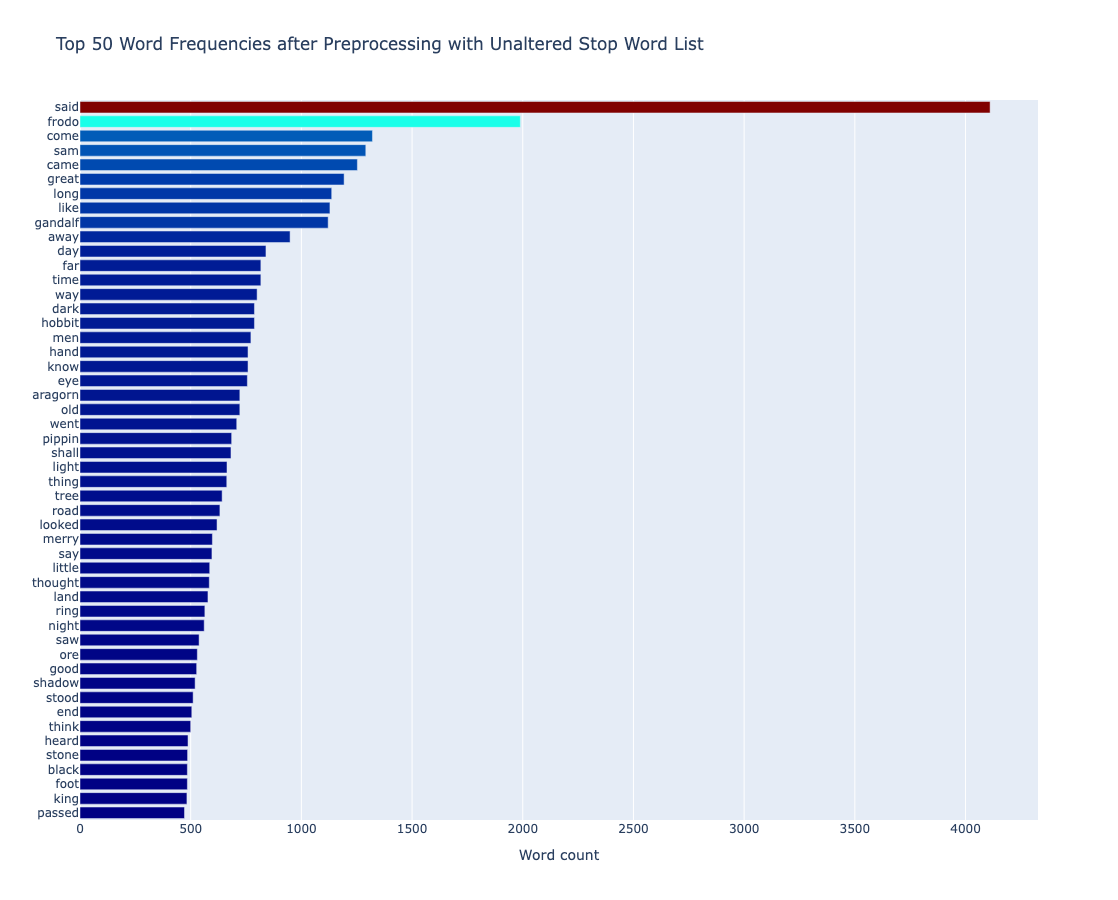

In [25]:
import plotly.offline as py
py.init_notebook_mode(connected=True)
import plotly.graph_objs as go

feature_names = tf_vectorizer.get_feature_names_out()
count_vec = np.asarray(tf.sum(axis=0)).ravel()
zipped = list(zip(feature_names, count_vec))
x, y = (list(x) for x in zip(*sorted(zipped, key=lambda x: x[1], reverse=True)))

# Now I want to extract out on the top 15 and bottom 15 words
Y = np.concatenate([y[0:15], y[-16:-1]])
X = np.concatenate([x[0:15], x[-16:-1]])

# Plotting the Plot.ly plot for the Top 50 word frequencies (horizontal)
data = [go.Bar(
            x = y[0:50],                     # counts now run along the x-axis
            y = x[0:50],                     # words now run along the y-axis
            orientation = 'h',
            marker = dict(colorscale='Jet',
                          color = y[0:50]
                         ),
            hovertemplate = '%{y}: %{x}<extra></extra>'
    )]

layout = go.Layout(
    title='Top 50 Word Frequencies after Preprocessing with Unaltered Stop Word List',
    xaxis = dict(title='Word count'),
    yaxis = dict(autorange='reversed'),      # puts the most frequent word at the top
    height = 900                             # tall enough that all 50 labels are readable
)

fig = go.Figure(data=data, layout=layout)

py.iplot(fig, filename='basic-bar')

In [40]:
# Knowing how sensitive LDA models can be regarding word counts; I'm reticent to remove any additional stopwords. 


stopwords = nltk.corpus.stopwords.words('english')  # changing this list can have a dramatic effect on topic modelling
                                                    # because they use word counts (LDA more that NMF models)
    
stopwords.append('said') # removed due to disproportional frequency
stopwords.append('come')
stopwords.append('came')
stopwords.append('think')
stopwords.append('heard')
stopwords.append('saw')
stopwords.append('say')
stopwords.append('looked')
stopwords.append('thing')
stopwords.append('went')
stopwords.append('shall')
stopwords.append('away')
stopwords.append('like')
stopwords.append('thing')
stopwords.append('let')
stopwords.append('way')

# Additional stopwords, like proper names, could dramatically alter results. Keeping them to preserve the text. 

In [41]:
# Remove stopwords using our new list
lotr_clean = [word for word in lotr_tokens if word.lower() not in stopwords]

In [42]:
print(stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [43]:
# Lemmatize tokens.
lemmatizer = WordNetLemmatizer()
lotr_tokens_lems = [lemmatizer.lemmatize(i) for i in lotr_clean]

In [44]:
# Calling our overwritten Count vectorizer
tf_vectorizer = LemmaCountVectorizer(max_df=0.95, 
                                     min_df=2,
                                     stop_words='english',
                                     decode_error='ignore')
tf = tf_vectorizer.fit_transform(lotr_tokens_lems)

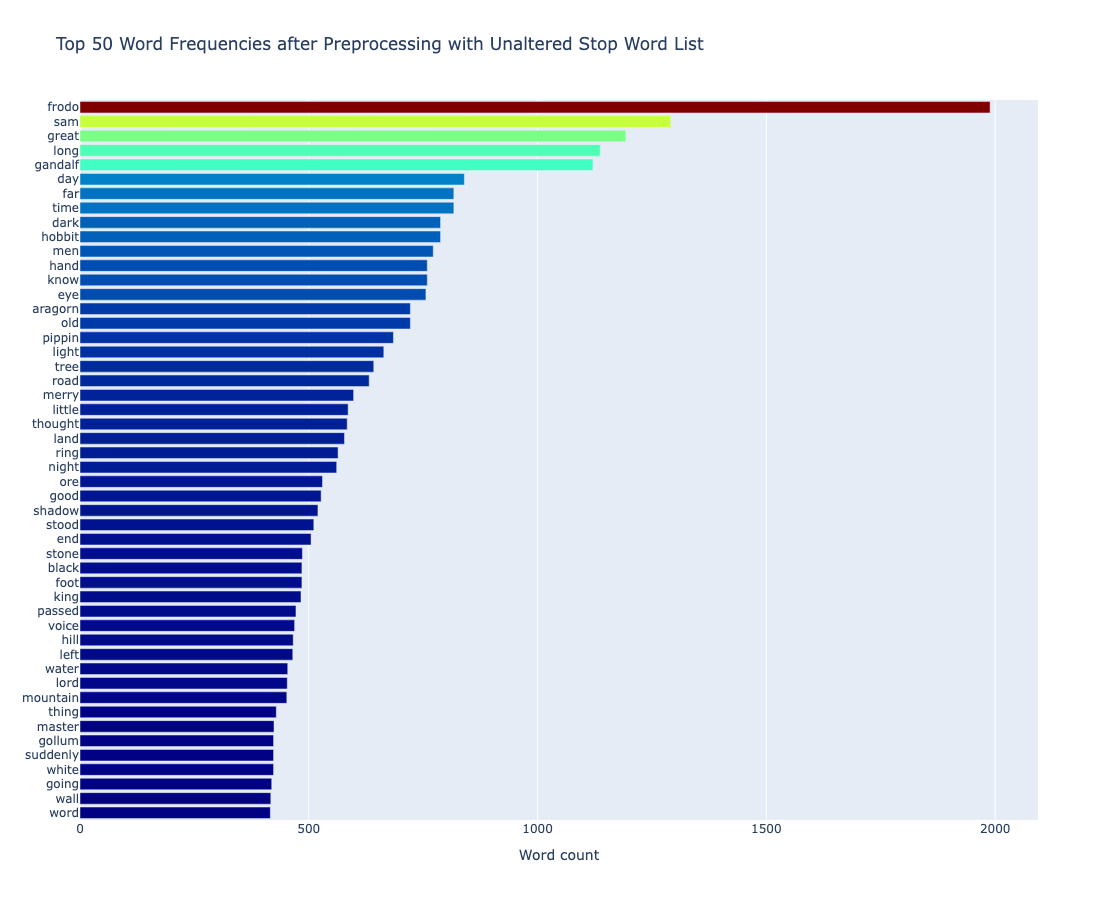

In [45]:
import plotly.offline as py
py.init_notebook_mode(connected=True)
import plotly.graph_objs as go

feature_names = tf_vectorizer.get_feature_names_out()
count_vec = np.asarray(tf.sum(axis=0)).ravel()
zipped = list(zip(feature_names, count_vec))
x, y = (list(x) for x in zip(*sorted(zipped, key=lambda x: x[1], reverse=True)))

# Now I want to extract out on the top 15 and bottom 15 words
Y = np.concatenate([y[0:15], y[-16:-1]])
X = np.concatenate([x[0:15], x[-16:-1]])

# Plotting the Plot.ly plot for the Top 50 word frequencies (horizontal)
data = [go.Bar(
            x = y[0:50],                     # counts now run along the x-axis
            y = x[0:50],                     # words now run along the y-axis
            orientation = 'h',
            marker = dict(colorscale='Jet',
                          color = y[0:50]
                         ),
            hovertemplate = '%{y}: %{x}<extra></extra>'
    )]

layout = go.Layout(
    title='Top 50 Word Frequencies after Preprocessing with Unaltered Stop Word List',
    xaxis = dict(title='Word count'),
    yaxis = dict(autorange='reversed'),      # puts the most frequent word at the top
    height = 900                             # tall enough that all 50 labels are readable
)

fig = go.Figure(data=data, layout=layout)

py.iplot(fig, filename='basic-hbar')

fig.write_html('./word_freqs_unaltered_stopwords')

In [38]:
from pathlib import Path

# 1. Create the folder (does nothing if it already exists)
Path('templates').mkdir(exist_ok=True)

# 2. The HTML template text
template_html = """<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>{{ page_title }}</title>
  <style>
    body { font-family: system-ui, sans-serif; margin: 2rem auto; max-width: 1000px; padding: 0 1rem; }
    h1   { font-size: 1.4rem; }
    .note { color: #555; }
  </style>
</head>
<body>
  <h1>{{ page_title }}</h1>
  <p class="note">{{ description }}</p>
  {{ fig | safe }}
</body>
</html>
"""

# 3. Save it as a file inside that folder
Path('templates/word_freq_template.html').write_text(template_html, encoding='utf-8')

# 4. Confirm it worked
print(sorted(p.name for p in Path('templates').iterdir()))

['.ipynb_checkpoints', 'word_freq_template.html']


#### I'm comfortable with Frodo and Sam being at the top of our word frequencies since they're the main characters. 